In [2]:
import os
os.environ["TF_METAL_DEVICE_DISABLE"] = "1"  # Disable TensorFlow-Metal

import tensorflow as tf
print("Using devices:", tf.config.list_physical_devices())  # Should list only CPU



Using devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [1]:
!ls track3


Autonomous_car.ipynb road_data
Untitled.ipynb       steering_angles.csv


In [72]:
import tensorflow as tf
print(tf.__version__)
print(tf.config.list_physical_devices())


2.16.2
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [73]:
import tensorflow as tf

# Check if GPU is being used
print("GPU Available:", tf.config.list_physical_devices('GPU'))

# Run a small matrix multiplication on GPU
with tf.device('/GPU:0'):
    a = tf.constant([[1.0, 2.0], [3.0, 4.0]])
    b = tf.constant([[5.0, 6.0], [7.0, 8.0]])
    c = tf.matmul(a, b)

print("Matrix multiplication result:\n", c.numpy())


GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Matrix multiplication result:
 [[19. 22.]
 [43. 50.]]


2025-03-15 14:17:55.909928: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2
2025-03-15 14:17:55.910850: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2025-03-15 14:17:55.910858: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
2025-03-15 14:17:55.911627: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-03-15 14:17:55.912305: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [1]:
!pip3 install imgaug
from PIL import Image, ImageFile
import os
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import keras
from keras.models import Sequential, load_model
from keras.optimizers import Adam
from keras.layers import Convolution2D, MaxPooling2D, Dropout, Flatten, Dense
from sklearn.utils import shuffle
from keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from imgaug import augmenters as iaa
import cv2
import pandas as pd
import ntpath
import random
from collections import Counter

In [13]:
# datadir = 'track3'
# columns = ['center','steering']

# data['steering'] = data['steering'] - 90
# data.head()

In [2]:
# print(data.iloc[1])
def load_img_steering():
  image_path = []
  steering = []
  # os
  for file in os.listdir("track3/road_data"):
    if file.endswith(".jpg"):
            image_path.append(os.path.join("track3/road_data", file))
            file = str(file)
            steering_angle = file.split("_")[-1].split(".")[0]
            steering_angle = int(steering_angle) - 90
            steering.append(steering_angle)

  image_path = np.asarray(image_path)
  steering = np.asarray(steering)
  return image_path, steering

image_paths, steerings = load_img_steering()

In [3]:
mean = np.mean(steerings)
std_dev = np.std(steerings)

In [4]:
counts = Counter(steerings)

In [5]:
print(counts)

Counter({0: 1538, -10: 730, 10: 724, 20: 396, -20: 263, 30: 50, -30: 11, 40: 5, 50: 3})


In [56]:
import numpy as np
import matplotlib.pyplot as plt



def expected_frequencies(steering_angles, total_samples, std_dev):
    expec_freq =[]
    """
    Calculate the expected frequency of each steering angle to fit a normal distribution centered at zero.

    Parameters:
    - steering_angles (numpy array): Unique steering angles in the dataset.
    - total_samples (int): Total number of data points.
    - std_dev (float): Standard deviation (σ) controlling the spread.

    Returns:
    - dict: Expected frequency for each steering angle.
    """
    mean = 0  # Set mean to zero

    # Calculate probabilities using the Normal Distribution formula
    probabilities = np.exp(-((steering_angles - mean) ** 2) / (2 * std_dev ** 2))
    probabilities /= (std_dev * np.sqrt(2 * np.pi))  # Normalize

    # Convert probabilities into expected frequencies
    expected_counts = (probabilities / np.sum(probabilities)) * total_samples

    freq_dict = dict(zip(steering_angles, expected_counts))

    # Print frequencies
    print("\nExpected Frequencies for Each Steering Angle:")
    
    for angle, freq in freq_dict.items():
        expec_freq.append(int(freq))
        # print(f"Angle {angle}: {int(freq)} samples")  # Convert float to int for better readability

    return expec_freq

def plot_expected_distribution(expected_freqs, std_dev):
    """
    Plots a histogram of the expected frequencies.

    Parameters:
    - expected_freqs (dict): Expected frequency of each steering angle.
    - std_dev (float): Standard deviation (σ) used in the distribution.
    """
    angles = list(expected_freqs.keys())
    counts = list(expected_freqs.values())

    plt.figure(figsize=(10, 5))
    plt.bar(angles, counts, color='skyblue', edgecolor='black', width=5)
    
    plt.xlabel("Steering Angles", fontsize=14)
    plt.ylabel("Expected Frequency", fontsize=14)
    plt.title(f"Expected Normal Distribution of Steering Angles (μ=0, σ={std_dev})", fontsize=16)
    plt.grid(axis="y", linestyle="--", alpha=0.7)

    plt.show()

# Example Usage
steering_angles = np.array([-30, -20, -10, 0, 10, 20, 30, 40])  # Unique steering angles
total_samples = 100  # Assume we want 1000 total data points
std_dev = 35  # You can change this value to control spread

expected_freqs = expected_frequencies(steering_angles, total_samples, std_dev)
plot_expected_distribution(expected_freqs, std_dev)



Expected Frequencies for Each Steering Angle:


AttributeError: 'list' object has no attribute 'keys'

In [9]:
expec_freq

[10, 13, 14, 15, 14, 13, 10, 7]

In [14]:
filtered_values = steerings[steerings > 40]
# Print the result
print(filtered_values)

filtered_values2 = steerings[steerings < -40]

print(filtered_values2)

steering_angles = []
for angle in steerings:
  if (angle > 40):
    angle = 40
  if (angle < -40):
    angle = -40
  steering_angles.append(angle)

steerings = np.array(steering_angles)



[50 50 50]
[]


In [15]:
# import numpy as np

# Example data
# image_paths = np.array(["img1.jpg", "img2.jpg", "img3.jpg", "img4.jpg", "img5.jpg", "img6.jpg"])
# steerings = np.array([-10, 0, 10, 20, 30, 40])  # Example values

# Create a dictionary to store arrays
steering_dict = {}

# Loop through unique values in steerings
for value in np.unique(steerings):
    indices = np.where(steerings == value)  # Get indices of matching values
    steering_dict[value] = image_paths[indices]  # Assign corresponding image paths

# Print result
# for key, val in steering_dict.items():
#     print(f"Steering {key}:{val}")


In [12]:
print(mean)
print(std_dev)

1.10752688172043
35


In [13]:
image_paths.shape

(3720,)

In [78]:
# Checking for corrupted images


# ImageFile.LOAD_TRUNCATED_IMAGES = True

# def check_corrupt_images(image_paths, steering_angles):
#     valid_image_paths = []
#     valid_steering_angles = []

#     for img_path, angle in zip(image_paths, steering_angles):
#         try:
#             with Image.open(img_path) as img:
#                 img = img.convert("RGB")  # Convert to RGB mode
#                 img.load()


#             # If no exception, add to valid lists
#             valid_image_paths.append(img_path)
#             valid_steering_angles.append(angle)

#         except (IOError, OSError) as e:
#             print(f"Corrupted image found: {img_path} ({str(e)})")
#             try:
#                 os.remove(img_path)  # Delete the corrupted image
#                 print(f"Deleted: {img_path}")
#             except Exception as remove_error:
#                 print(f"Could not delete {img_path}: {remove_error}")

#     # Convert to NumPy arrays
#     valid_image_paths = np.array(valid_image_paths)
#     valid_steering_angles = np.array(valid_steering_angles)

#     print(f"Valid images count: {len(valid_image_paths)}")
#     print(f"Valid steering angles count: {len(valid_steering_angles)}")

#     return valid_image_paths, valid_steering_angles

# # Example usage
# image_paths, steerings = check_corrupt_images(image_paths, steerings)


Valid images count: 3720
Valid steering angles count: 3720


In [105]:
image_paths.shape, steerings.shape

((3720,), (3720,))

In [179]:
num_unique = np.unique(steerings)
print(num_unique)

[-30 -20 -10   0  10  20  30  40]


In [193]:
# import numpy as np

# Ensure steering_angles is a 1D NumPy array
steering_angles = np.array(steerings).flatten()

# Get indices of zero and non-zero steering angles
zero_indices = np.where(steering_angles == 0)[0]
non_zero_indices = np.where(steering_angles != 0)[0]

# Keep only 400 zero-angle samples
selected_zero_indices = np.random.choice(zero_indices, min(850, len(zero_indices)), replace=False)

# Combine selected zero and all non-zero indices
final_indices = np.concatenate((selected_zero_indices, non_zero_indices))

# Shuffle indices
np.random.shuffle(final_indices)

# Filter the dataset
balanced_image_paths = np.array(image_paths)[final_indices]
balanced_steering_angles = np.array(steering_angles)[final_indices]



print("Original dataset size:", len(image_paths))
print("Balanced dataset size:", len(balanced_image_paths))

image_paths = balanced_image_paths
steerings = balanced_steering_angles


Original dataset size: 3720
Balanced dataset size: 3032


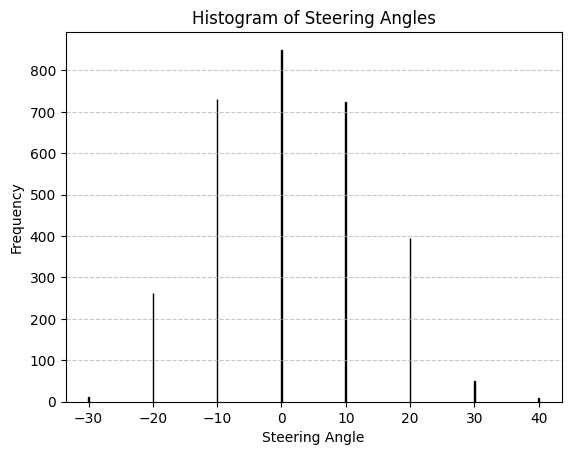

In [194]:
#Ploting before normalization

unique_values, counts = np.unique(steerings, return_counts=True)

# Plot the histogram
plt.bar(unique_values, counts, width=0.1, edgecolor="black")

# Labels and title
plt.xlabel("Steering Angle")
plt.ylabel("Frequency")
plt.title("Histogram of Steering Angles")
plt.xticks(unique_values)  # Ensure all unique values appear on x-axis
plt.grid(axis='y', linestyle="--", alpha=0.7)

# Show the plot
plt.show()

In [182]:
#Adding noise of +-2 in every steering angle
# noise = np.random.uniform(-1, 1, size=steerings.shape)

possible_values = np.arange(-1, 1.25, 0.25)

noise = np.random.choice(possible_values, size=steerings.shape)

# Keep zeros unchanged
noisy_steering_angles = np.where(steerings == 0, 0, steerings + noise)

# Clip values to stay within [-30, 40]
noisy_steering_angles = np.clip(noisy_steering_angles, -30, 40)

steerings = noisy_steering_angles

In [195]:
#Mapping values between -1 and 1

normalized_steering = np.where(
    steerings <= 0,
    steerings / 30.0,  # Scale negative values
    steerings / 40.0   # Scale positive values
)

steerings = normalized_steering

In [196]:
num_unique = np.unique(steerings)
print(num_unique)

[-1.         -0.66666667 -0.33333333  0.          0.25        0.5
  0.75        1.        ]


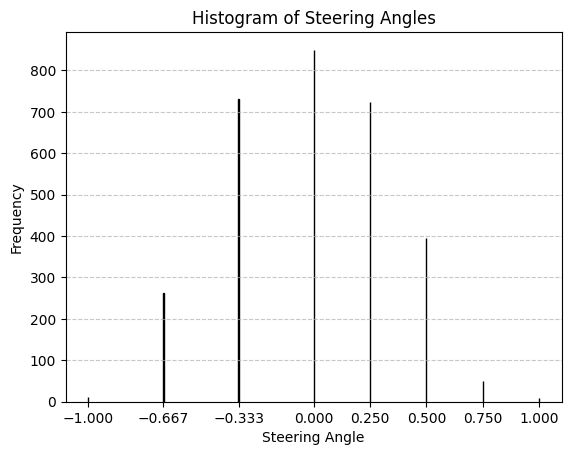

In [197]:
unique_values, counts = np.unique(steerings, return_counts=True)

# Plot the histogram
plt.bar(unique_values, counts, width=0.001, edgecolor="black")

# Labels and title
plt.xlabel("Steering Angle")
plt.ylabel("Frequency")
plt.title("Histogram of Steering Angles")
plt.xticks(unique_values)  # Ensure all unique values appear on x-axis
plt.grid(axis='y', linestyle="--", alpha=0.7)

# Show the plot
plt.show()

[-1.    -0.998 -0.996 ...  0.996  0.998  1.   ]


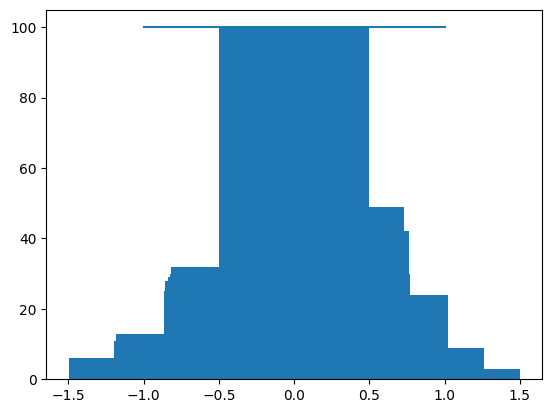

In [114]:
num_bins = 1000
samples_per_bin = 100
hist, bins = np.histogram(steerings, num_bins)
# dat = [x - 90.0 for x in bins]
dat = bins
print(dat)
center = (dat[:-1] + dat[1:]) * 0.5
# print(dat)
plt.bar(center, hist, width=1)
plt.plot((np.min(steerings), np.max(steerings)), (samples_per_bin, samples_per_bin))

In [198]:
num_unique = np.unique(steerings)
print(num_unique)

[-1.         -0.66666667 -0.33333333  0.          0.25        0.5
  0.75        1.        ]


In [199]:
X_train, X_valid, y_train, y_valid = train_test_split(image_paths, steerings, test_size=0.20, random_state=6)
print('Training Samples: {}\nValid Samples: {}'.format(len(X_train), len(X_valid)))

Training Samples: 2425
Valid Samples: 607


Text(0.5, 1.0, 'Validation set')

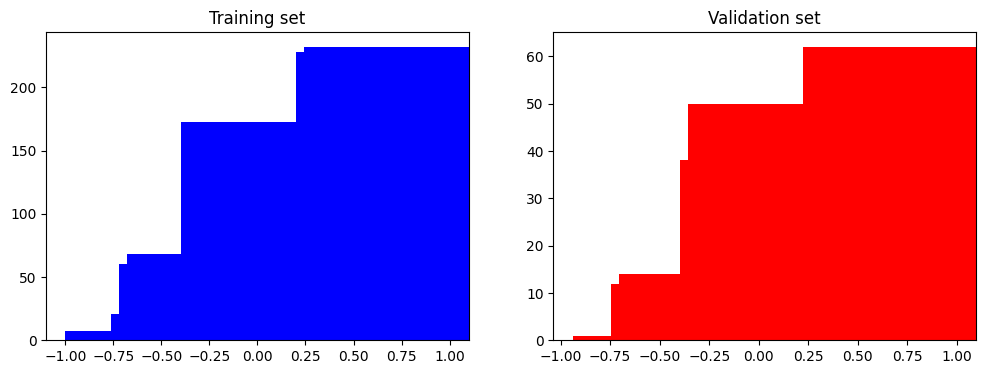

In [91]:
num_bins=50
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y_train, bins=num_bins, width=1, color='blue')
axes[0].set_title('Training set')
axes[1].hist(y_valid, bins=num_bins, width=1, color='red')
axes[1].set_title('Validation set')

In [200]:
def zoom(image):
  zoom = iaa.Affine(scale=(1, 1.3))
  image = zoom.augment_image(image)
  return image

In [201]:
def pan(image):
  pan = iaa.Affine(translate_percent= {"x" : (-0.06, 0.06), "y": (-0.06, 0.06)})
  image = pan.augment_image(image)
  return image

Text(0.5, 1.0, 'Brightness altered image ')

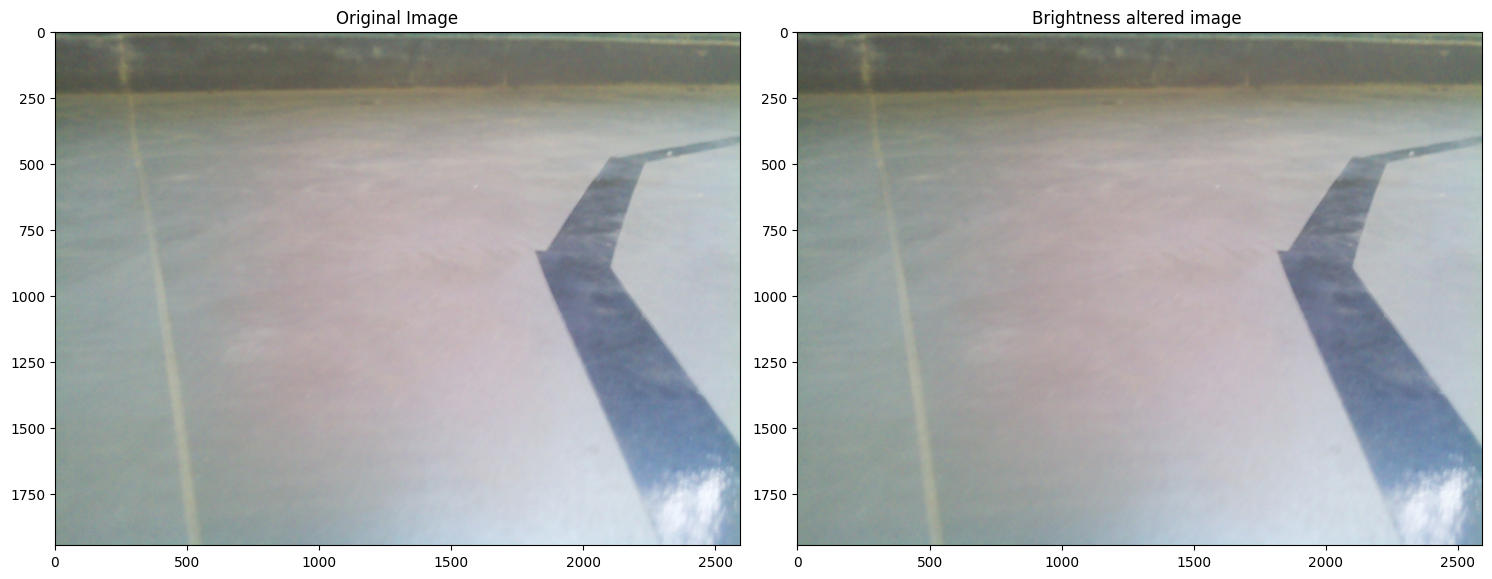

In [202]:
def img_random_brightness(image):
    brightness = iaa.Multiply((0.2, 1.2))
    image = brightness.augment_image(image)
    return image
image = image_paths[random.randint(0, 119)]
original_image = mpimg.imread(image)
brightness_altered_image = img_random_brightness(original_image)

fig, axs = plt.subplots(1, 2, figsize=(15, 10))
fig.tight_layout()

axs[0].imshow(original_image)
axs[0].set_title('Original Image')

axs[1].imshow(brightness_altered_image)
axs[1].set_title('Brightness altered image ')

In [24]:
def img_random_flip(image, steering_angle):
    image = cv2.flip(image,1)

    steering_angle =  -steering_angle
    return image, steering_angle


Text(0.5, 1.0, 'Flipped Image - Steering Angle:-20')

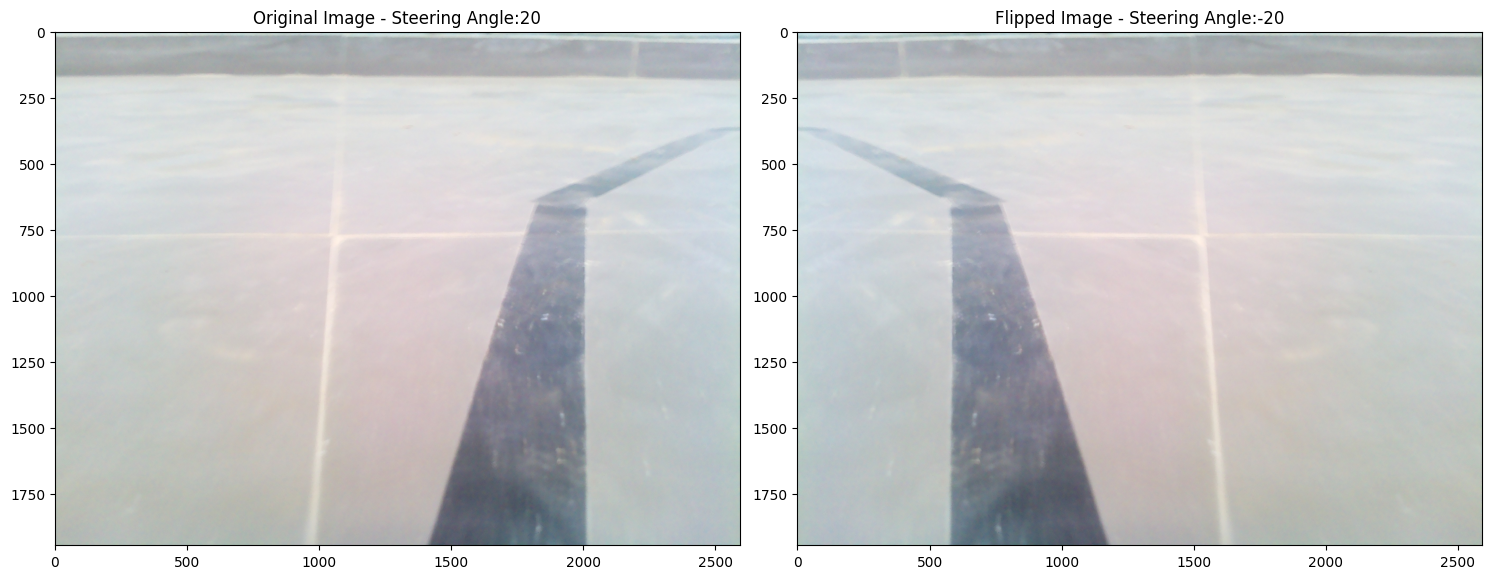

In [39]:
random_index = random.randint(0, 3000)
print(random_index)
image = image_paths[random_index]
steering_angle = steerings[random_index]


original_image = mpimg.imread(image)
flipped_image, flipped_steering_angle = img_random_flip(original_image, steering_angle)

fig, axs = plt.subplots(1, 2, figsize=(15, 10))
fig.tight_layout()

axs[0].imshow(original_image)
axs[0].set_title('Original Image - ' + 'Steering Angle:' + str(steering_angle))

axs[1].imshow(flipped_image)
axs[1].set_title('Flipped Image - ' + 'Steering Angle:' + str(flipped_steering_angle))

In [40]:
print(random_index)

1737


In [25]:
def random_augment(image, steering_angle):
    image = mpimg.imread(image)
    if np.random.rand() < 0.5:
      image = pan(image)
    if np.random.rand() < 0.5:
      image = zoom(image)
    if np.random.rand() < 0.5:
      image = img_random_brightness(image)
    if np.random.rand() < 0.5:
      image, steering = img_random_flip(image, steering_angle)

    return image, steering_angle

223


Text(0.5, 1.0, 'Preprocessed Image 10')

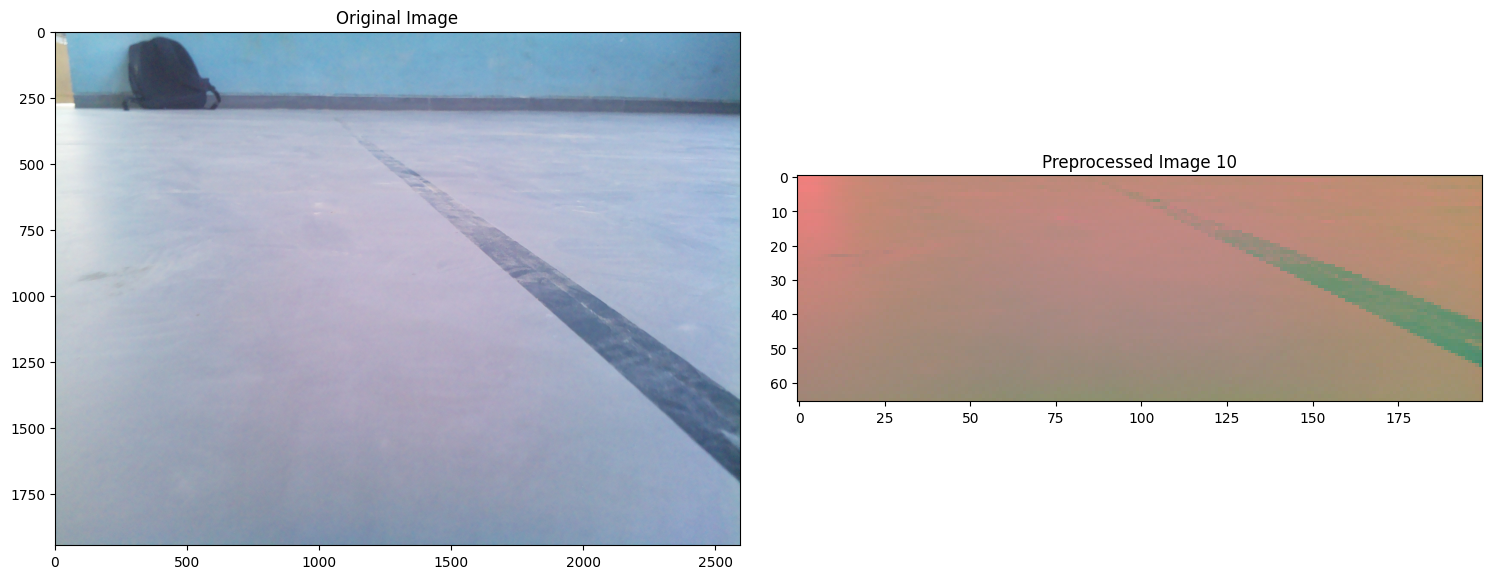

In [26]:
def img_preprocess(img):
    img = img[360:,:,:]
    img = cv2.cvtColor(img, cv2.COLOR_RGB2YUV)
    img = cv2.GaussianBlur(img,  (3, 3), 0)
    img = cv2.resize(img, (200, 66))
    img = img/255
    return img
num = random.randint(0, 1000)
print(num)
image = image_paths[num]
angle = steerings[num]
original_image = mpimg.imread(image)
preprocessed_image = img_preprocess(original_image)

fig, axs = plt.subplots(1, 2, figsize=(15, 10))
fig.tight_layout()
axs[0].imshow(original_image)
axs[0].set_title('Original Image')
axs[1].imshow(preprocessed_image)
axs[1].set_title(f'Preprocessed Image {angle}')

In [123]:
steerings

array([-0.33992777, -0.34035168, -0.36238845, ...,  0.48505106,
       -0.30169048, -0.36657174])

In [100]:
# import numpy as np
# # from tensorflow.keras.utils import to_categorical

# def categorical(array):
#     # Define the fixed mapping of unique values to indices
#     unique_values = np.array([-30, -20, -10, 0, 10, 20, 30, 40])  # 8 values

#     # Ensure all values in 'array' exist in 'unique_values'
#     if not np.isin(array, unique_values).all():
#         raise ValueError("Input array contains values not in predefined unique_values.")

#     # Map values to indices (0 to 7)
#     y_indices = np.array([np.where(unique_values == val)[0][0] for val in array])

#     # One-hot encode batch labels with fixed num_classes = 8
#     y_one_hot = to_categorical(y_indices, num_classes=8)

#     return y_one_hot



In [101]:
array = np.array([-30, -20, -10, 0, 10, 20, 30, 40])
new_array = array // 10
new_array = new_array + 3
print(new_array[1])

1


In [102]:
# def categorical(array):
#     # Convert values to indices (ensuring integer indices)
#     indices = (array // 10) + 3  # Mapping -30 → 0, ..., 40 → 7

#     # Initialize a one-hot encoded array
#     one_hot = np.zeros((array.shape[0], 8), dtype=float)  # Ensure dtype=float for 1.0

#     # Assign 1.0 at the correct index positions
#     for i in range(len(array)):
#         one_hot[i, indices[i]] = 1.0  # Correct indexing

#     return one_hot

# # Example usage
# y_train = np.array([-30, -20, -10, 0, 10, 20, 30, 40])
# one_hot_encoded = categorical(y_train)

# print(one_hot_encoded)

In [ ]:
std_dev = np.std(steerings)

In [48]:
# def batch_generator(steering_angles, steering_dict, batch_size, istraining):
#     expec_freq = expected_frequencies(steering_angles, batch_size, std_dev)
#     batch_img = []
#     batch_steering = []
#     for i in range(len(expec_freq)):
#         no_of_images = expec_freq[i]
#         steering_key = steering_angles[i]
#         for j in range(no_of_images):
#             dict = steering_dict[steering_key]
#             random_index = random.randint(0, len(dict) - 1)
    
#             if istraining:
#                 im, steering = random_augment(dict[random_index], steering_key)
                
#             else:
#                 im = mpimg.imread(dict[random_index])
#                 steering = steering_key
    
#             im = img_preprocess(im)
#             batch_img.append(im)
#             batch_steering.append(steering)
#     batch_img = np.asarray(batch_img, dtype=np.float32)  # Ensure proper data type
#     batch_steering = np.asarray(batch_steering, dtype=np.float32)    
    
#     yield (batch_img, batch_steering) # outputing a tuple of batch_img and batch_steering

In [43]:
# x_train_gen, y_train_gen = next(batch_generator(steering_angles, steering_dict, 1000, 0))
# x_valid_gen, y_valid_gen = next(batch_generator(steering_angles, steering_dict, 1000, 0))


Expected Frequencies for Each Steering Angle:
Angle -30: 106 samples
Angle -20: 130 samples
Angle -10: 147 samples
Angle 0: 153 samples
Angle 10: 147 samples
Angle 20: 130 samples
Angle 30: 106 samples
Angle 40: 79 samples

Expected Frequencies for Each Steering Angle:
Angle -30: 106 samples
Angle -20: 130 samples
Angle -10: 147 samples
Angle 0: 153 samples
Angle 10: 147 samples
Angle 20: 130 samples
Angle 30: 106 samples
Angle 40: 79 samples


In [47]:
def batch_generator(image_paths, steering_ang, batch_size, istraining):

  while True:
    batch_img = []
    batch_steering = []

    for i in range(batch_size):
      random_index = random.randint(0, len(image_paths) - 1)

      if istraining:
        im, steering = random_augment(image_paths[random_index], steering_ang[random_index])
      else:
        im = mpimg.imread(image_paths[random_index])
        steering = steering_ang[random_index]

      im = img_preprocess(im)
      batch_img.append(im)
      batch_steering.append(steering)

    batch_img = np.asarray(batch_img, dtype=np.float32)  # Ensure proper data type
    batch_steering = np.asarray(batch_steering, dtype=np.float32)
    # print(batch_steering)
    # batch_steering = categorical(batch_steering)
    # print(batch_img)
    # print(batch_steering)




    yield (batch_img, batch_steering) # outputing a tuple of batch_img and batch_steering

x_train_gen, y_train_gen = next(batch_generator(X_train, y_train, 20, 1))
x_valid_gen, y_valid_gen = next(batch_generator(X_valid, y_valid, 10, 0))

NameError: name 'X_train' is not defined

In [46]:
x_train_gen

array([[[[0.8980392 , 0.5254902 , 0.46666667],
         [0.90588236, 0.52156866, 0.4745098 ],
         [0.89411765, 0.5294118 , 0.4745098 ],
         ...,
         [0.8156863 , 0.50980395, 0.4745098 ],
         [0.81960785, 0.5137255 , 0.4745098 ],
         [0.8156863 , 0.5137255 , 0.45882353]],

        [[0.92156863, 0.5176471 , 0.48235294],
         [0.90588236, 0.52156866, 0.46666667],
         [0.9098039 , 0.5254902 , 0.47058824],
         ...,
         [0.81960785, 0.50980395, 0.48235294],
         [0.8156863 , 0.50980395, 0.48235294],
         [0.80784315, 0.50980395, 0.46666667]],

        [[0.90588236, 0.5294118 , 0.4745098 ],
         [0.9098039 , 0.52156866, 0.47843137],
         [0.9019608 , 0.5254902 , 0.46666667],
         ...,
         [0.8039216 , 0.5176471 , 0.47843137],
         [0.8039216 , 0.5137255 , 0.47843137],
         [0.8039216 , 0.50980395, 0.4627451 ]],

        ...,

        [[0.54901963, 0.5921569 , 0.39215687],
         [0.5372549 , 0.59607846, 0.40392157]

Text(0.5, 1.0, 'Validation Image')

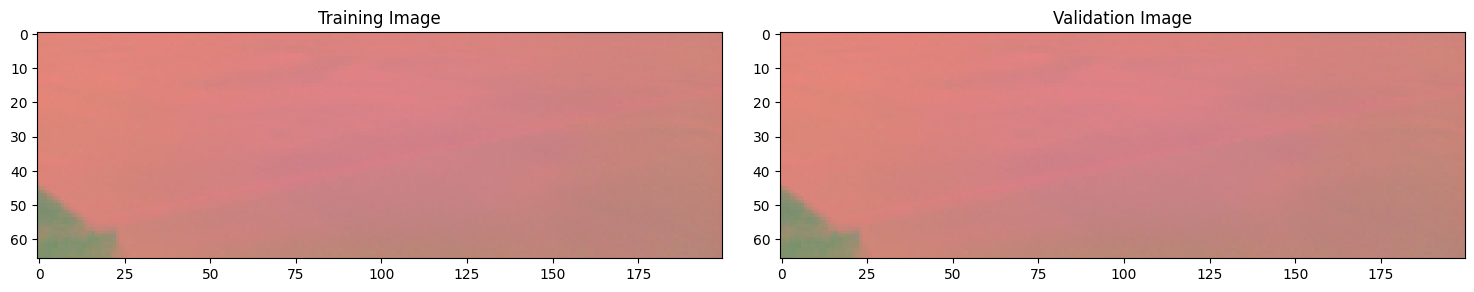

In [44]:
fig, axs = plt.subplots(1, 2, figsize=(15, 10))
fig.tight_layout()

axs[0].imshow(x_train_gen[8])
axs[0].set_title('Training Image')

axs[1].imshow(x_valid_gen[8])
axs[1].set_title('Validation Image')

In [50]:
# def nvidia_model():
#   model = Sequential()
#   model.add(Convolution2D(24, (5, 5), strides =(2, 2),activation='elu', input_shape=(66, 200, 3)))
#   model.add(Convolution2D(36, (5, 5), strides =(2, 2), activation='elu'))
#   model.add(Convolution2D(48, (5, 5), strides =(2, 2), activation='elu'))
#   model.add(Convolution2D(64, (3, 3), activation='elu'))

#   model.add(Convolution2D(64, 3, 3, activation='elu'))
#   model.add(Dropout(0.5))


#   model.add(Flatten())

#   model.add(Dense(100, activation = 'elu'))
#   model.add(Dropout(0.5))

#   model.add(Dense(50, activation = 'elu'))
#   model.add(Dropout(0.2))

#   model.add(Dense(10, activation = 'elu'))
#   # model.add(Dropout(0.5))

#   model.add(Dense(1, activation = 'linear'))

#   optimizer = Adam(learning_rate=1e-4)
#   model.compile(loss='mse', optimizer=optimizer)
#   return model

In [51]:
model = nvidia_model()
print(model.summary())

<venv>/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2025-04-10 14:37:14.979042: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2
2025-04-10 14:37:14.979168: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2025-04-10 14:37:14.979174: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
2025-04-10 14:37:14.979514: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-04-10 14:37:14.979950: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created Tensor

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 31, 98, 24)     │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 47, 36)     │        21,636 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 5, 22, 48)      │        43,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 3, 20, 64)      │        27,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 1, 6, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 384)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │        38,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 50)             │         5,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           510 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,419 (685.23 KB)

 Trainable params: 175,419 (685.23 KB)

 Non-trainable params: 0 (0.00 B)

None


In [52]:
np.unique(y_train)

NameError: name 'y_train' is not defined

In [57]:
history = model.fit(
    batch_generator(steering_angles, steering_dict, 100, 0),  # Generator function
    steps_per_epoch=220,
    epochs=10,
    validation_data = batch_generator(steering_angles, steering_dict, 80, 0),
    validation_steps = 100,
    verbose=1,
    shuffle=True  # `shuffle` should be `True`, not `1`
)


Expected Frequencies for Each Steering Angle:
Epoch 1/10
  1/220 ━━━━━━━━━━━━━━━━━━━━ 52s 241ms/step - loss: 440.2856
Expected Frequencies for Each Steering Angle:


2025-04-10 14:38:53.605884: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
	 [[{{node IteratorGetNext}}]]
2025-04-10 14:38:53.605916: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 12041545438413669918
2025-04-10 14:38:53.605943: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 4718987109339695656
2025-04-10 14:38:53.605947: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 16713714887092800384
2025-04-10 14:38:53.605952: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
	 [[{{node IteratorGetNext}}]]
	 [[StatefulPartitionedCall/gradient_tape/sequential_1/conv2d_3_1/EluGrad/_196]]
2025-04-10 14:38:53.605958: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv

220/220 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 440.2856 - val_loss: 441.4188
Epoch 2/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 190us/step - loss: 437.5105 - val_loss: 441.1426
Epoch 3/10


2025-04-10 14:38:55.203716: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
	 [[{{node IteratorGetNext}}]]
2025-04-10 14:38:55.203735: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
	 [[{{node IteratorGetNext}}]]
	 [[StatefulPartitionedCall/sequential_1/conv2d_1/Elu/_12]]
2025-04-10 14:38:55.203744: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 7480826924140929127
2025-04-10 14:38:55.203746: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 12647321481443148393
2025-04-10 14:38:55.203752: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 888077380086383539
2025-04-10 14:38:55.203755: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key ha

220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 146us/step - loss: 437.6468 - val_loss: 440.8908
Epoch 4/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 149us/step - loss: 428.3477 - val_loss: 440.6460
Epoch 5/10


...

2025-04-10 14:38:55.790614: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
	 [[{{node IteratorGetNext}}]]
2025-04-10 14:38:55.790627: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 10415472593590263534
2025-04-10 14:38:55.790630: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 7511364560698012166
2025-04-10 14:38:55.790632: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 1185758112672683318
2025-04-10 14:38:55.790635: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 3671255436643186128
2025-04-10 14:38:55.790637: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 4720400916264970378
2025-04-10 14:38:55.790639: I tensorflow/core/framework/local_rendezvo

220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 146us/step - loss: 440.4285 - val_loss: 439.9479
Epoch 8/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 170us/step - loss: 435.5373 - val_loss: 439.7233
Epoch 9/10


2025-04-10 14:38:56.059683: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
	 [[{{node IteratorGetNext}}]]
2025-04-10 14:38:56.059701: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 15581912370536457788
2025-04-10 14:38:56.059707: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 4720400916264970378
2025-04-10 14:38:56.059710: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
	 [[{{node IteratorGetNext}}]]
	 [[StatefulPartitionedCall/gradient_tape/sequential_1/conv2d_3_1/EluGrad/_196]]
2025-04-10 14:38:56.059722: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 8958105957740223930
2025-04-10 14:38:56.059728: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv 

220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 153us/step - loss: 436.5963 - val_loss: 439.5011
Epoch 10/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 168us/step - loss: 430.3192 - val_loss: 439.2675


2025-04-10 14:38:56.364856: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
	 [[{{node IteratorGetNext}}]]
2025-04-10 14:38:56.364868: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 9311061770761347290
2025-04-10 14:38:56.364871: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 9872443337770164748
2025-04-10 14:38:56.364874: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 12041545438413669918
2025-04-10 14:38:56.364876: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 4720400916264970378
2025-04-10 14:38:56.364879: I tensorflow/core/framework/local_rendezvous.cc:422] Local rendezvous recv item cancelled. Key hash: 4718987109339695656
2025-04-10 14:38:56.364881: I tensorflow/core/framework/local_rendezvo

Text(0.5, 0, 'Epoch')

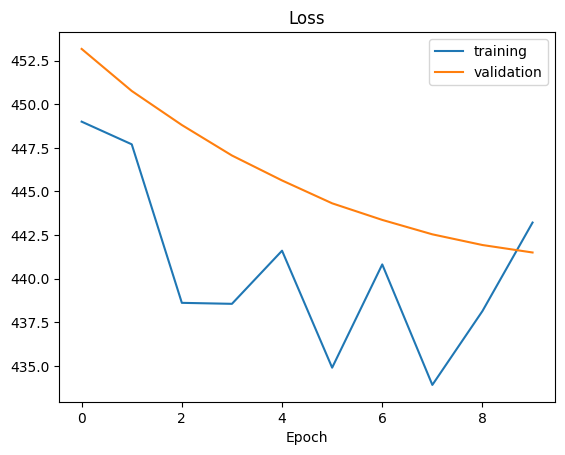

In [55]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.legend(['training', 'validation'])
plt.title('Loss')
plt.xlabel('Epoch')

In [218]:
model.save('my_model-15mar-1710-2.keras')


In [2]:
def img_preprocess(img):
    img = img[360:,:,:]
    img = cv2.cvtColor(img, cv2.COLOR_RGB2YUV)
    img = cv2.GaussianBlur(img,  (3, 3), 0)
    img = cv2.resize(img, (200, 66))
    img = img/255
    print(img.shape)
    return img

2766
(66, 200, 3)
Time taken: 0.013243913650512695 seconds
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step
Model Prediction: [[0.01075581 0.09284087 0.50507426 0.0380246  0.06179989 0.25852758
  0.02708795 0.00588905]]
Time taken: 0.0005488395690917969 seconds
-10


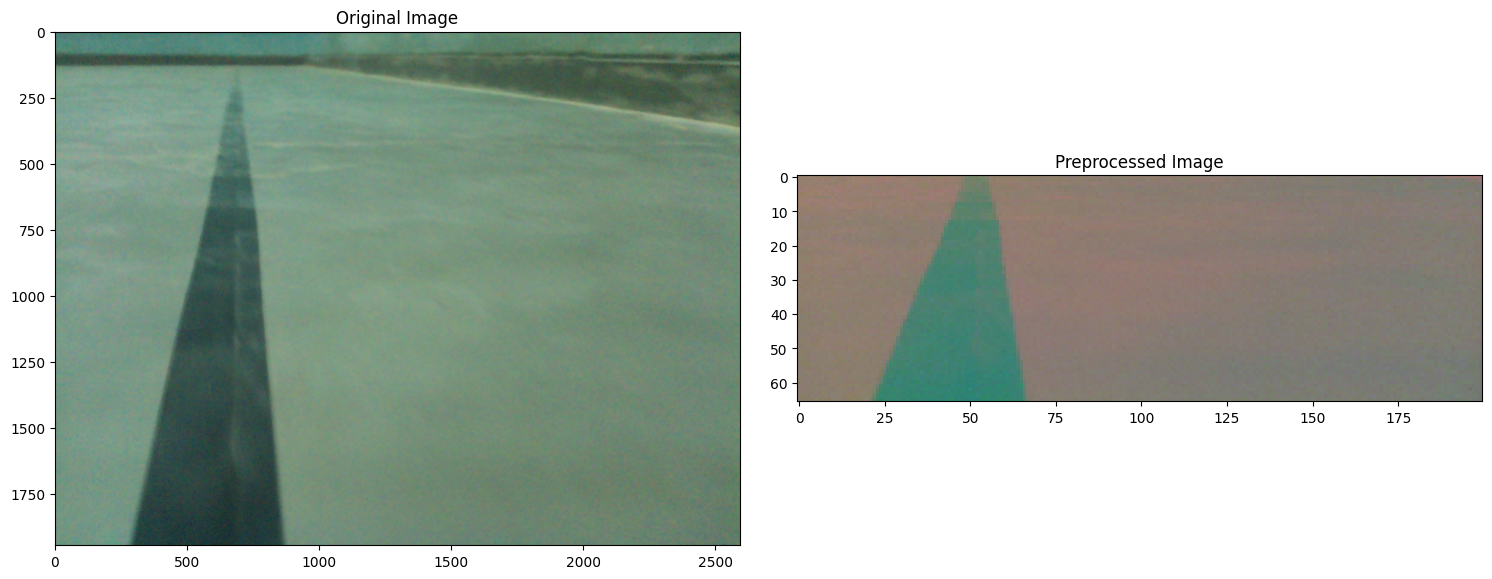

In [13]:
import time
num = random.randint(0, 3000)
# num = 2674
print(num)
image = image_paths[num]
# image = "track3/road_data/img_20250315_050018_angle_120.jpg"
original_image = mpimg.imread(image)
start_time = time.time()
preprocessed_image = img_preprocess(original_image)
# print(preprocessed_image.shape)
end_time = time.time()

# Calculate elapsed time
elapsed_time = end_time - start_time
print(f"Time taken: {elapsed_time} seconds")


fig, axs = plt.subplots(1, 2, figsize=(15, 10))
fig.tight_layout()
axs[0].imshow(original_image)
axs[0].set_title('Original Image')
axs[1].imshow(preprocessed_image)
axs[1].set_title('Preprocessed Image')
model = load_model("Models/my_model2.keras")  # Replace with your model's path

# Prepare input data (example: a single image for a self-driving car model)
input_data = preprocessed_image     #np.random.rand(1, 66, 200, 3)  # Shape (batch_size, height, width, channels)
input_data = np.expand_dims(preprocessed_image, axis=0)  # Shape becomes (1, 66, 200, 3)

# Make prediction
prediction = model.predict(input_data)
start_time = time.time()
# Output the predicted values
print("Model Prediction:", prediction)
end_time = time.time()

# Calculate elapsed time
elapsed_time = end_time - start_time
print(f"Time taken: {elapsed_time} seconds")
angle_mapping = [-30, -20, -10, 0, 10, 20, 30, 40]
predicted_index = np.argmax(prediction)
predicted_angle = angle_mapping[predicted_index]
print(predicted_angle)

Selected Image Index: 2674
(66, 200, 3)
Predicted Steering Angle: [[0.03490898 0.07539031 0.15679836 0.27829048 0.23071238 0.14805096
  0.04288864 0.0329599 ]]
0


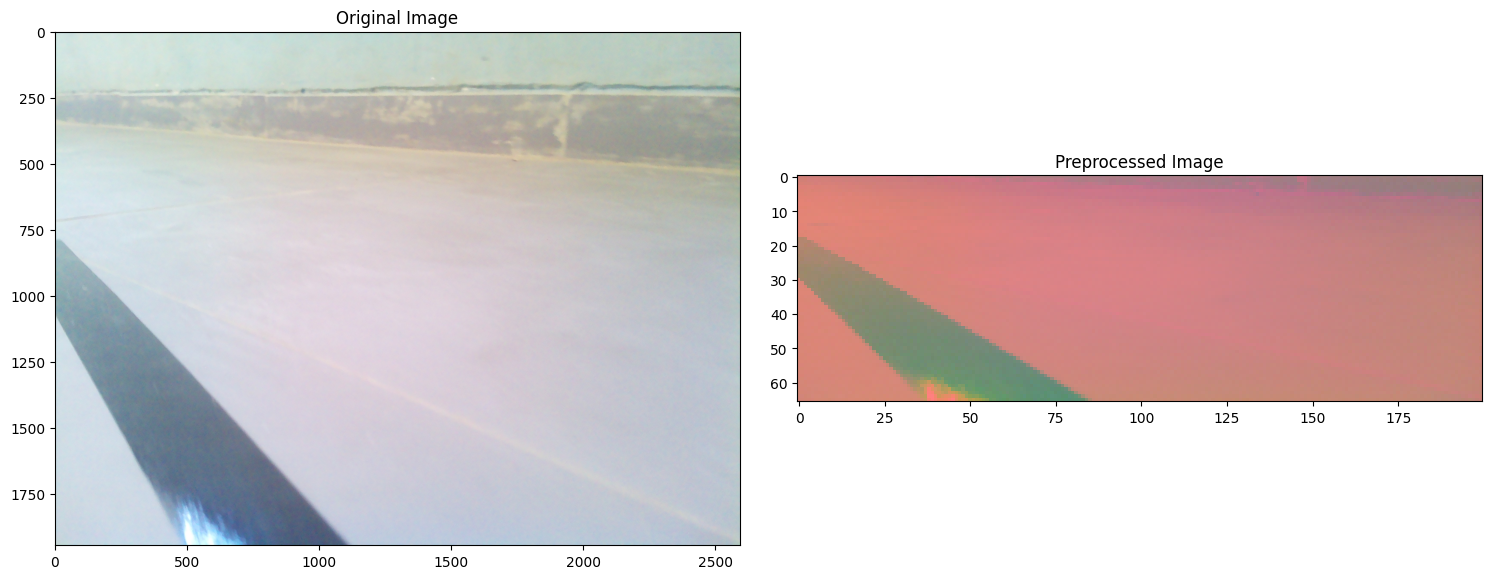

In [37]:
import tensorflow as tf
import numpy as np
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cv2  # For image preprocessing

# Load the TFLite model
def load_tflite_model(model_path):
    interpreter = tf.lite.Interpreter(model_path=model_path)
    interpreter.allocate_tensors()
    return interpreter

# Run inference using the TFLite model
def run_inference(interpreter, input_image):
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    # Ensure input matches model shape
    input_shape = input_details[0]['shape']
    input_image = cv2.resize(input_image, (200, 66))  # Resize to match input shape
    input_image = input_image.astype(np.float32) / 255.0  # Normalize pixel values
    input_image = np.expand_dims(input_image, axis=0)  # Add batch dimension (1, 66, 200, 3)

    # Set input tensor
    interpreter.set_tensor(input_details[0]['index'], input_image)

    # Run inference
    interpreter.invoke()

    # Get the output tensor (steering angle prediction)
    output_data = interpreter.get_tensor(output_details[0]['index'])
    return output_data  # Return the predicted steering angle

# Load the TFLite model
tflite_model_path = "my_modelfull32.tflite"  # Change to your TFLite model path
interpreter = load_tflite_model(tflite_model_path)

# Select a random image
# num = random.randint(0, 3000)
num = 2674
print("Selected Image Index:", num)

image = image_paths[num]  # Replace with the actual dataset path
original_image = mpimg.imread(image)

# Preprocess image (Assuming img_preprocess is defined)
preprocessed_image = img_preprocess(original_image)

# Display Original and Preprocessed Image
fig, axs = plt.subplots(1, 2, figsize=(15, 10))
fig.tight_layout()
axs[0].imshow(original_image)
axs[0].set_title('Original Image')
axs[1].imshow(preprocessed_image)
axs[1].set_title('Preprocessed Image')

# Run inference on the TFLite model
steering_angle = run_inference(interpreter, preprocessed_image)

# Output the predicted steering angle
print("Predicted Steering Angle:", steering_angle)

angle_mapping = [-30, -20, -10, 0, 10, 20, 30, 40]
predicted_index = np.argmax(steering_angle)
predicted_angle = angle_mapping[predicted_index]
print(predicted_angle)

In [19]:
angle_mapping = [-30, -20, -10, 0, 10, 20, 30, 40]
predicted_index = np.argmax(prediction)
predicted_angle = angle_mapping[predicted_index]
print(predicted_angle)

-10
